# Exploratory analysis: Polish air quality 2019–2026

**Goal:** understand the PM2.5 data before forecasting it 24–48 h ahead: data
quality, long-term trend, seasonal and daily cycles, geography, and how weather
drives pollution. Each section ends with what it means for the model.

Data: hourly GIOŚ measurements (official yearly archives 2019–2025 + API for 2026)
and Open-Meteo ERA5 weather, loaded into PostgreSQL by this project's pipeline.
Heavy aggregation is done in SQL; pandas only receives the summarised result.

In [1]:
import numpy as np
import pandas as pd
from sqlalchemy import text

from airquality.db import get_engine
from airquality.viz import SEQ_BLUE, SERIES, apply_style, plt, save, threshold_line

apply_style()
engine = get_engine()


def q(sql: str, **params) -> pd.DataFrame:
    return pd.read_sql(text(sql), engine, params=params)

## 1. Data coverage and quality

In [2]:
coverage = q("""
    SELECT pollutant, extract(year FROM ts_utc)::int AS year,
           count(DISTINCT station_code) AS stations,
           count(*) AS hours,
           round(100.0 * avg((value IS NULL)::int), 1) AS pct_missing
      FROM measurements GROUP BY 1, 2 ORDER BY 1, 2
""")
coverage.pivot(index="year", columns="pollutant", values=["stations", "pct_missing"])

stations              pct_missing           
pollutant      NO2   PM10 PM2.5         NO2 PM10 PM2.5
year                                                  
2019         123.0  117.0  52.0         2.3  3.8   4.2
2020         121.0  131.0  61.0         2.5  3.2   3.7
2021         122.0  145.0  70.0         2.1  2.2   2.6
2022         121.0  141.0  70.0         2.6  2.5   3.2
2023         123.0  151.0  73.0         2.6  3.0   3.2
2024         125.0  156.0  76.0         3.6  3.3   3.1
2025         127.0  173.0  91.0         2.4  2.9   2.2
2026          54.0   45.0  13.0         0.0  0.0   0.0

The PM2.5 network grew from ~50 to ~90 stations; missing data is a stable 2–4 %.
2026 is partial (API data, still loading at the time of writing).

Which stations have a usable PM2.5 history? Share of valid hours per station and year:

stations with >=75% coverage in every year 2019-2025: 39


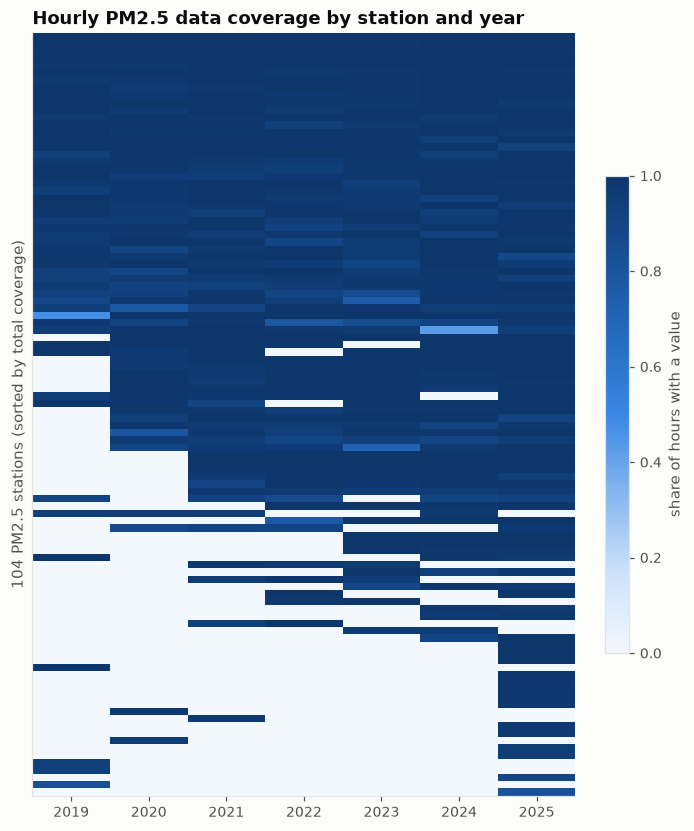

In [3]:
avail = q("""
    SELECT station_code, extract(year FROM ts_utc)::int AS year,
           count(value)::float / (CASE WHEN extract(year FROM ts_utc)::int % 4 = 0
                                       THEN 8784 ELSE 8760 END) AS share
      FROM measurements
     WHERE pollutant = 'PM2.5' AND source = 'archive_xlsx'
     GROUP BY 1, 2
""").pivot(index="station_code", columns="year", values="share").fillna(0)
avail = avail.loc[avail.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(7, 9))
im = ax.imshow(avail.values, aspect="auto", cmap=SEQ_BLUE, vmin=0, vmax=1)
ax.set_xticks(range(len(avail.columns)), avail.columns)
ax.set_yticks([])
ax.set_ylabel(f"{len(avail)} PM2.5 stations (sorted by total coverage)")
ax.set_title("Hourly PM2.5 data coverage by station and year")
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.04, label="share of hours with a value")
save(fig, "coverage_heatmap")
full = int((avail.loc[:, 2019:2025] >= 0.75).all(axis=1).sum())
print(f"stations with >=75% coverage in every year 2019-2025: {full}")

**For the model:** many stations joined the network after 2019, so the training
set is an unbalanced panel. Train on all station-hours with a value rather than
only on stations with complete history, and use time-based (not random) splits.

### Distribution of hourly values

count    2045258.0
mean          15.1
std           14.2
min            0.0
50%           11.1
90%           29.6
99%           70.6
99.9%        137.5
max          450.5
skewness raw: 4.2   skewness log1p: 0.18


WindowsPath('D:/airquality/reports/figures/distribution.png')

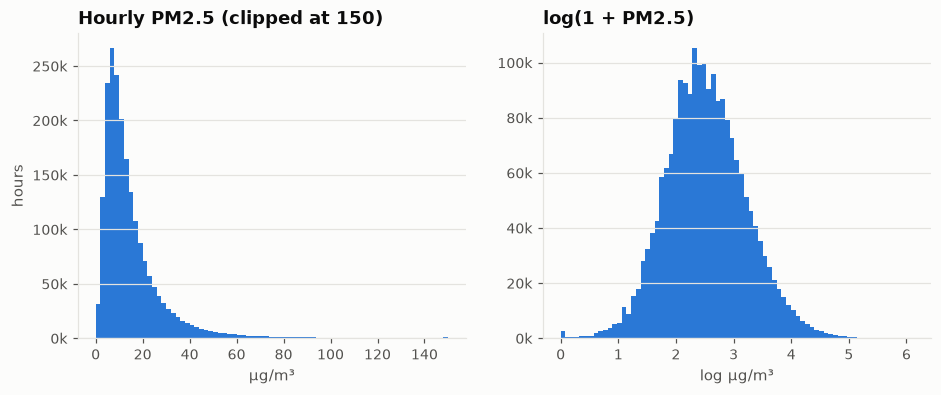

In [4]:
dist = q("""
    SELECT value FROM measurements
     WHERE pollutant = 'PM2.5' AND value IS NOT NULL
       AND ts_utc >= '2023-01-01' AND ts_utc < '2026-01-01'
""")["value"]
print(dist.describe(percentiles=[0.5, 0.9, 0.99, 0.999]).round(1).to_string())
print(f"skewness raw: {dist.skew():.1f}   skewness log1p: {np.log1p(dist).skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(dist.clip(upper=150), bins=75, color=SERIES[0])
axes[0].set(title="Hourly PM2.5 (clipped at 150)", xlabel="µg/m³", ylabel="hours")
axes[1].hist(np.log1p(dist), bins=75, color=SERIES[0])
axes[1].set(title="log(1 + PM2.5)", xlabel="log µg/m³")
for ax in axes:
    ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
save(fig, "distribution")

**For the model:** strongly right-skewed with rare extreme smog episodes.
Training on `log1p(PM2.5)` makes the target roughly symmetric and stops a few
episodes dominating a squared-error loss. Report errors back on the original scale.

## 2. Long-term trend vs. health standards

,year,mean_pm25,share_days_over_who
0,2019,19.399,0.512
1,2020,16.612,0.414
2,2021,19.156,0.469
3,2022,16.014,0.396
4,2023,14.555,0.345
5,2024,15.089,0.357
6,2025,15.511,0.355


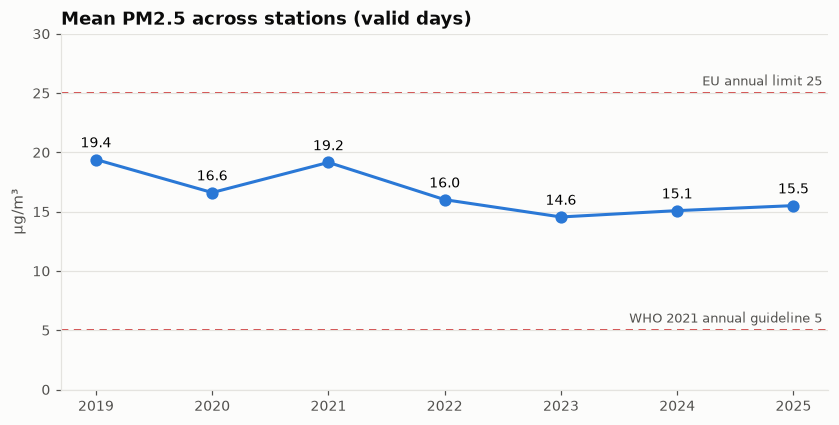

In [5]:
annual = q("""
    SELECT extract(year FROM day)::int AS year, avg(mean_value) AS mean_pm25,
           avg((mean_value > 15)::int) AS share_days_over_who
      FROM daily_station
     WHERE pollutant = 'PM2.5' AND is_valid AND day < '2026-01-01'
     GROUP BY 1 ORDER BY 1
""")

fig, ax = plt.subplots()
ax.plot(annual["year"], annual["mean_pm25"], marker="o", ms=7, color=SERIES[0])
for _, r in annual.iterrows():
    ax.annotate(f"{r.mean_pm25:.1f}", (r.year, r.mean_pm25), xytext=(0, 8),
                textcoords="offset points", ha="center", fontsize=9)
threshold_line(ax, 25, "EU annual limit 25")
threshold_line(ax, 5, "WHO 2021 annual guideline 5")
ax.set(ylim=(0, 30), ylabel="µg/m³", title="Mean PM2.5 across stations (valid days)")
save(fig, "annual_trend")
annual.round(3)

Mean PM2.5 fell ~20 % between 2019 and 2025. The network average now meets the
EU annual limit but remains about 3× the WHO 2021 guideline, and roughly a
third of station-days still exceed the WHO daily guideline (15 µg/m³).

## 3. Seasonal, weekly and daily cycles

WindowsPath('D:/airquality/reports/figures/monthly_boxplot.png')

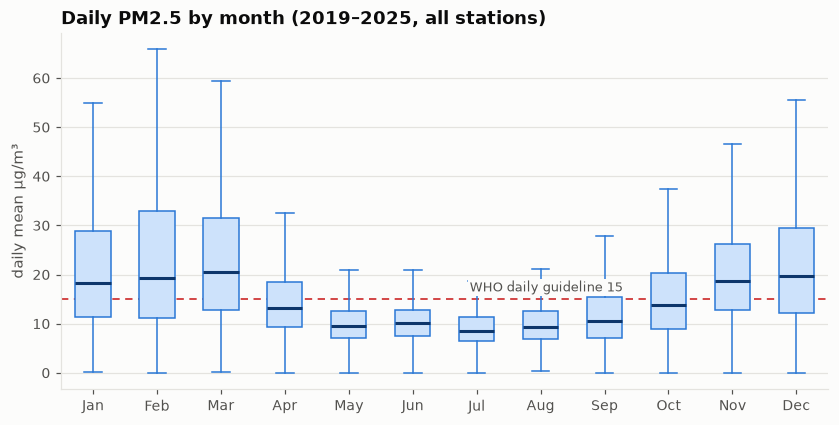

In [6]:
monthly = q("""
    SELECT extract(month FROM day)::int AS month, mean_value
      FROM daily_station
     WHERE pollutant = 'PM2.5' AND is_valid AND day < '2026-01-01'
""")
fig, ax = plt.subplots()
data = [monthly.loc[monthly.month == m, "mean_value"] for m in range(1, 13)]
ax.boxplot(data, showfliers=False, widths=0.55, patch_artist=True,
           boxprops=dict(facecolor="#cde2fb", edgecolor=SERIES[0]),
           medianprops=dict(color="#0d366b", lw=2), whiskerprops=dict(color=SERIES[0]),
           capprops=dict(color=SERIES[0]))
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                             "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
threshold_line(ax, 15, "WHO daily guideline 15", x=0.74)  # over the low summer boxes
ax.set(ylabel="daily mean µg/m³", title="Daily PM2.5 by month (2019–2025, all stations)")
save(fig, "monthly_boxplot")

A clear **heating-season** pattern: October–March daily means are about twice
the summer level and far more variable. Winter is where forecasting matters most.

WindowsPath('D:/airquality/reports/figures/diurnal_cycle.png')

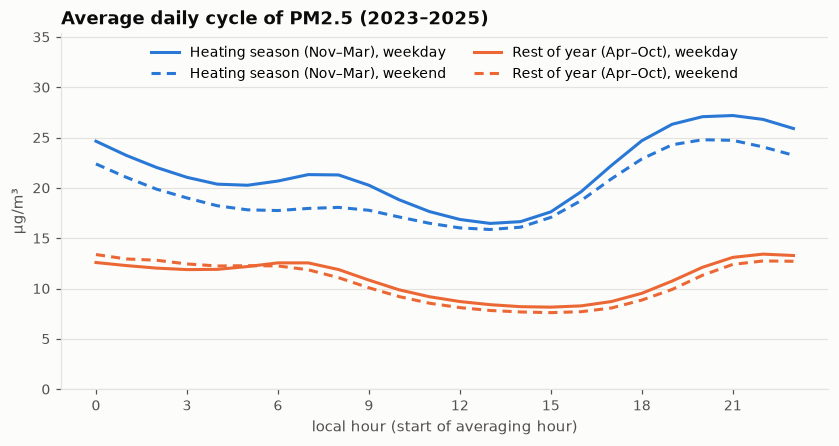

In [7]:
diurnal = q("""
    SELECT CASE WHEN extract(month FROM local_ts) IN (11,12,1,2,3) THEN 'Heating season (Nov–Mar)'
                ELSE 'Rest of year (Apr–Oct)' END AS season,
           extract(hour FROM local_ts)::int AS hour,
           extract(isodow FROM local_ts) >= 6 AS weekend,
           avg(value) AS pm25
      FROM (SELECT (ts_utc - interval '1 hour') AT TIME ZONE 'Europe/Warsaw' AS local_ts, value
              FROM measurements
             WHERE pollutant = 'PM2.5' AND ts_utc >= '2023-01-01' AND ts_utc < '2026-01-01') x
     GROUP BY 1, 2, 3
""")
fig, ax = plt.subplots()
styles = {False: "-", True: (0, (3, 2))}
for i, season in enumerate(["Heating season (Nov–Mar)", "Rest of year (Apr–Oct)"]):
    for weekend in (False, True):
        d = diurnal[(diurnal.season == season) & (diurnal.weekend == weekend)].sort_values("hour")
        label = f"{season}, {'weekend' if weekend else 'weekday'}"
        ax.plot(d.hour, d.pm25, color=SERIES[i], ls=styles[weekend], label=label)
ax.set_xticks(range(0, 24, 3))
ax.set(xlabel="local hour (start of averaging hour)", ylabel="µg/m³",
       title="Average daily cycle of PM2.5 (2023–2025)")
ax.legend(ncols=2, loc="upper center")
ax.set_ylim(0, diurnal.pm25.max() * 1.3)
save(fig, "diurnal_cycle")

In winter PM2.5 peaks in the **evening** (home heating, plus a shallow night-time
boundary layer) and dips in the afternoon when the atmosphere mixes best.
In summer the cycle is much flatter. Weekends are only ~1–2 µg/m³ lower than
weekdays, so traffic contributes but is secondary. The winter-evening peak (when
people get home and heat their houses) is the dominant pattern.

**For the model:** hour-of-day, month and day-of-week are useful features, and
their effect differs by season, so a tree model that captures interactions is a
sensible choice.

## 4. Geography

,city,station_code,pm25
85,Krotoszyn,WpKrotoOlimpMOB,26.3
80,Żywiec,SlZywieKoper,25.7
73,Bielsko-Biała,SlBielPartyz,22.5
39,Żyrardów,MzZyraRoosev,20.6
84,Kalisz,WpKaliSawick,20.4
75,Jastrzębie-Zdrój,SlJastrZdroj,19.9
2,Kłodzko,DsKlodzSzkol,19.5
28,Otwock,MzOtwoBrzozo,19.4
14,Łask,LdLaskNarutoMOB,19.3
10,Włocławek,KpWloclOkrze,18.9


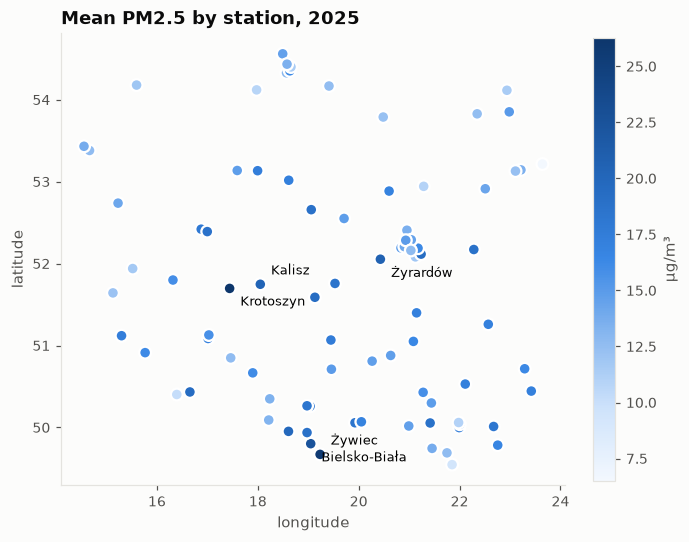

In [8]:
geo = q("""
    SELECT s.station_code, s.city, s.latitude, s.longitude, avg(d.mean_value) AS pm25,
           count(*) AS days
      FROM daily_station d JOIN stations s USING (station_code)
     WHERE d.pollutant = 'PM2.5' AND d.is_valid AND d.day >= '2025-01-01' AND d.day < '2026-01-01'
     GROUP BY 1, 2, 3, 4 HAVING count(*) >= 270
""")
fig, ax = plt.subplots(figsize=(6.5, 6))
sc = ax.scatter(geo.longitude, geo.latitude, c=geo.pm25, cmap=SEQ_BLUE, s=60,
                edgecolor="white", linewidth=1.5, vmin=geo.pm25.min(), vmax=geo.pm25.max())
top = geo.nlargest(5, "pm25").sort_values("longitude")
for (_, r), dy in zip(top.iterrows(), [-9, 9, -9, 9, -9], strict=True):  # alternate to avoid overlap
    ax.annotate(r.city, (r.longitude, r.latitude), xytext=(7, dy), textcoords="offset points",
                fontsize=8.5, va="center")
ax.set(xlabel="longitude", ylabel="latitude", title="Mean PM2.5 by station, 2025")
ax.set_aspect(1 / np.cos(np.radians(52)))
ax.grid(False)
fig.colorbar(sc, ax=ax, fraction=0.04, label="µg/m³")
save(fig, "station_map")
geo.sort_values("pm25", ascending=False).head(10)[["city", "station_code", "pm25"]].round(1)

The highest levels are in the **south** (Żywiec and Bielsko-Biała in the Silesian
Beskids, where valleys trap air and coal heating is common) and in a few towns in
**central-western** Poland (Kalisz, Krotoszyn). The north and north-east are cleanest.
Two of the top ten are temporary mobile stations (`…MOB` codes), so they cover
shorter periods than the fixed stations.

**Kraków** was 4th worst of 42 cities in 2019 (24.8 µg/m³) and 18th of 72 in 2025
(17.6 µg/m³), a 29 % fall. That fits its ban on solid-fuel heating (in force since
September 2019), although the data alone can't prove that the ban caused it.

**For the model:** station identity and location matter. Including latitude and
longitude (or a station encoding) lets one global model learn regional baselines.

## 5. Persistence: how much does the past predict the future?

WindowsPath('D:/airquality/reports/figures/autocorrelation.png')

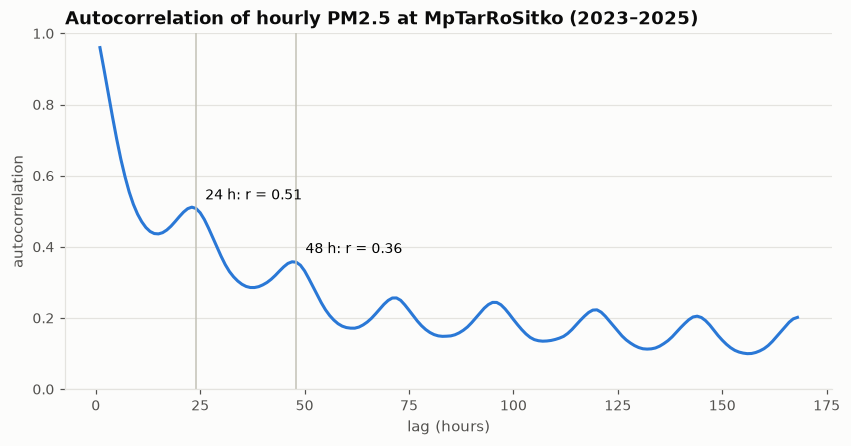

In [9]:
station = q("""
    SELECT station_code FROM measurements
     WHERE pollutant = 'PM2.5' AND source = 'archive_xlsx' AND value IS NOT NULL
     GROUP BY 1 ORDER BY count(*) DESC LIMIT 1
""").iloc[0, 0]
series = q("""
    SELECT ts_utc, value FROM measurements
     WHERE station_code = :s AND pollutant = 'PM2.5'
       AND ts_utc >= '2023-01-01' AND ts_utc < '2026-01-01'
     ORDER BY ts_utc
""", s=station).set_index("ts_utc")["value"].asfreq("h")
lags = np.arange(1, 7 * 24 + 1)
acf = [series.autocorr(int(k)) for k in lags]
fig, ax = plt.subplots()
ax.plot(lags, acf, color=SERIES[0])
for k in (24, 48):
    ax.axvline(k, color="#c3c2b7", lw=1)
    ax.annotate(f"{k} h: r = {acf[k - 1]:.2f}", (k, acf[k - 1]), xytext=(6, 6),
                textcoords="offset points", fontsize=9)
ax.set(xlabel="lag (hours)", ylabel="autocorrelation", ylim=(0, 1),
       title=f"Autocorrelation of hourly PM2.5 at {station} (2023–2025)")
save(fig, "autocorrelation")

PM2.5 is very persistent at short lags and still clearly correlated a day or two
later, with small daily bumps. **For the model:** "same as now" and "same as
yesterday" are strong baselines that any ML model must beat. Recent lags and
rolling means are the core features.

## 6. Weather drivers

Joining PM2.5 with ERA5 weather for the same station and hour. (The weather
backfill is rate-limited by the free API and was still in progress; this section
uses whatever is loaded, see the date range printed below.)

In [10]:
wx = q("""
    SELECT m.value AS pm25, w.temperature_2m, w.wind_speed_10m, w.boundary_layer_height,
           w.relative_humidity_2m, w.precipitation, m.ts_utc
      FROM measurements m
      JOIN weather_hourly w USING (station_code, ts_utc)
     WHERE m.pollutant = 'PM2.5' AND m.value IS NOT NULL AND w.source = 'archive'
       AND random() < 0.25
""")
print(f"{len(wx):,} joined station-hours (25 % sample), "
      f"{wx.ts_utc.min():%Y-%m-%d} to {wx.ts_utc.max():%Y-%m-%d}")

353,642 joined station-hours (25 % sample), 2019-01-01 to 2022-01-02


pm25                     1.00
temperature_2m          -0.42
wind_speed_10m          -0.22
boundary_layer_height   -0.47
relative_humidity_2m     0.30
Name: pm25, dtype: float64

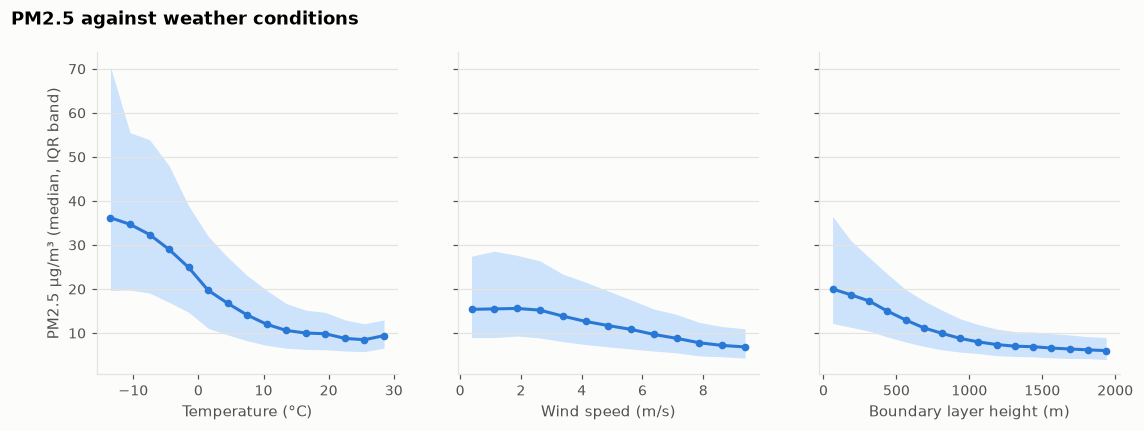

In [11]:
drivers = [
    ("temperature_2m", "Temperature (°C)", np.arange(-15, 31, 3)),
    ("wind_speed_10m", "Wind speed (m/s)", np.arange(0, 10.5, 0.75)),
    ("boundary_layer_height", "Boundary layer height (m)", np.arange(0, 2001, 125)),
]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, (col, label, bins) in zip(axes, drivers, strict=True):
    d = wx.dropna(subset=[col])
    g = d.groupby(pd.cut(d[col], bins), observed=True)["pm25"]
    mid = [iv.mid for iv in g.median().index]
    ax.fill_between(mid, g.quantile(0.25), g.quantile(0.75), color="#cde2fb", lw=0)
    ax.plot(mid, g.median(), color=SERIES[0], marker="o", ms=4)
    ax.set(xlabel=label)
axes[0].set_ylabel("PM2.5 µg/m³ (median, IQR band)")
fig.suptitle("PM2.5 against weather conditions", x=0.06, ha="left", fontweight="bold")
save(fig, "weather_drivers")
wx[["pm25", "temperature_2m", "wind_speed_10m", "boundary_layer_height",
    "relative_humidity_2m"]].corr(method="spearman")["pm25"].round(2)

The physics shows up clearly:
- **Cold** → more heating emissions → higher PM2.5.
- **Calm wind** → pollution is not dispersed.
- **Low boundary layer** (a shallow mixing layer, typical of winter inversions)
  → pollution is trapped near the ground. Smog episodes need all three together.

**For the model:** forecast weather for the target hour (temperature, wind,
boundary layer height) should add real skill on top of persistence, especially
for predicting when an episode starts or ends. Note the known data gap:
`boundary_layer_height` is missing in ERA5 for Jan–Jun 2024, so the model must
tolerate missing values (LightGBM does natively).

## Summary: implications for forecasting

| Finding | Modelling decision |
|---|---|
| Right-skewed target with rare extremes | Train on `log1p(PM2.5)`, evaluate in µg/m³ |
| Strong persistence (high short-lag autocorrelation) | Persistence & seasonal-naive baselines; lag/rolling features |
| Heating-season and diurnal cycles that interact | Calendar features + tree-based model (LightGBM) |
| Regional differences | One global model with station location features |
| Weather drives episodes | Forecast weather for the target hour as features |
| Network grows over time, some gaps | Time-based CV on all available station-hours; NaN-tolerant model |